# Normalization

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/02-data-preparation/normalization/normalization-notebook.ipynb)

Companion notebook for the *Normalization* slides. Each scaler is written first by hand
with NumPy and then with the scikit-learn class that does the same job.

**Data:** the Wine recognition data (178 wines, 13 chemical measurements).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing, load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

RANDOM_STATE = 42

wine = load_wine(as_frame=True)
features, labels = wine.data, wine.target
features.agg(["min", "max"]).T.sort_values("max", ascending=False).head()

,min,max
proline,278.00,1680.00
magnesium,70.00,162.00
alcalinity_of_ash,10.60,30.00
alcohol,11.03,14.83
color_intensity,1.28,13.00


`proline` reaches the thousands while most features stay below 10. Without scaling,
distances between wines are decided almost only by `proline`.

## 1. Min-max scaling

$x'_{ij} = \dfrac{x_{ij} - \min_j}{\max_j - \min_j}$ maps every feature to $[0, 1]$.

In [2]:
X = features.to_numpy()
min_max_by_hand =(X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0))
print("same result:", np.allclose(min_max_by_hand, MinMaxScaler().fit_transform(X)))

same result: True


## 2. Standardization

$z_{ij} = \dfrac{x_{ij} - \bar{x}_j}{s_j}$ gives each feature mean 0 and standard deviation 1.

In [3]:
standard_by_hand = (X - X.mean(axis=0)) / X.std(axis=0)
print("same result:", np.allclose(standard_by_hand, StandardScaler().fit_transform(X)))

same result: True


## 3. Robust scaling

$x'_{ij} = \dfrac{x_{ij} - \tilde{x}_j}{Q_3 - Q_1}$ uses the median and the quartiles,
so one extreme value barely moves it.

In [4]:
q1, median, q3 = np.percentile(X, [25, 50, 75], axis=0)
robust_by_hand = (X - median) / (q3 - q1)
print("same result:", np.allclose(robust_by_hand, RobustScaler().fit_transform(X)))

same result: True


## 4. Fit on training rows, apply to new rows

The mean and standard deviation are learned from the training rows only.
Test rows are scaled with those same numbers.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, labels, test_size=0.3, random_state=RANDOM_STATE, stratify=labels)

train_mean, train_std = X_train.mean(axis=0), X_train.std(axis=0)
test_by_hand = (X_test - train_mean) / train_std

scaler = StandardScaler().fit(X_train)
print("same result:", np.allclose(test_by_hand, scaler.transform(X_test)))

same result: True


## 5. Why it matters

k-nearest neighbors works with distances, so it changes a lot with scaling.
A pipeline fits the scaler on the training rows for us.

In [6]:
raw_knn = KNeighborsClassifier().fit(X_train, y_train)
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier()).fit(X_train, y_train)
print(f"raw features:    test accuracy {raw_knn.score(X_test, y_test):.3f}")
print(f"scaled features: test accuracy {scaled_knn.score(X_test, y_test):.3f}")

raw features:    test accuracy 0.722
scaled features: test accuracy 0.944


## 6. Log transform for a long tail

Some features have a few huge values, like the population of a district in the
California housing data. $\log_{10}(1 + x)$ spreads out the small values and pulls in the big ones.

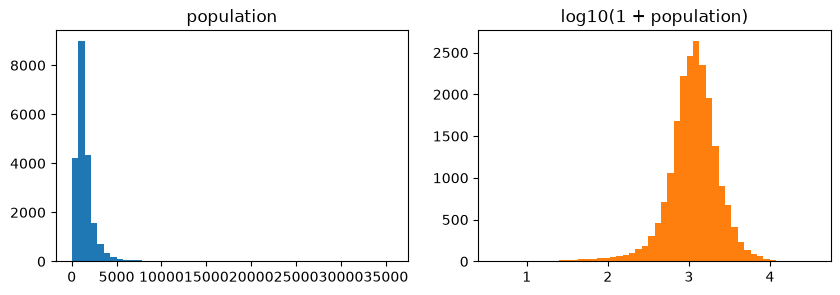

In [7]:
population = fetch_california_housing(as_frame=True).frame["Population"].to_numpy()

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3))
left.hist(population, bins=50)
left.set_title("population")
right.hist(np.log10(1 + population), bins=50, color="tab:orange")
right.set_title("log10(1 + population)")
plt.show()

## Exercises

1. Repeat section 5 with min-max and robust scaling. Which one works best here?
2. Scale the whole data set before splitting, then split. Which numbers did the scaler learn from the test rows?
3. Train a decision tree on raw and on scaled features. Why does its accuracy not change?